In [1]:
%config InlineBackend.figure_format = 'retina'

from pathlib import Path

import matplotlib.pyplot as plt
from IPython.display import display

from cognitive_maps_in_llms.analysis import RunResults, plot_mosaic_series


In [2]:
REPO_ROOT = next(
    path for path in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (path / 'src' / 'cognitive_maps_in_llms').is_dir()
)

# SET INPUT AND OUTPUT PATHS

# ------------------------------------------------------------------------------
RESULTS_ROOT = REPO_ROOT / 'results/final_run_2026-09-30'
FIGURES_DIR  = REPO_ROOT / 'figures/generated/main_text/figure_3'
SAVE_FIGURES = True
# ------------------------------------------------------------------------------

if SAVE_FIGURES:
    FIGURES_DIR.mkdir(parents=True, exist_ok=True)


In [3]:
# DEFINE HELPER TO MAKE A SINGLE ADDITIVITY PLOT

MODEL_PRESET = 'gemma-27b'
PROMPT_PRESET = 'ABC_family_tree_who_is'
EXPERIMENT = 'exp_3_additivity'
CONTROL_CONDITION = 'CTRL'
SWAP_CONDITION = 'SWAP'
RESULTS = RunResults(results_root=RESULTS_ROOT)

def plot_figure_3_query(query: str, title: str, filename: str):
    control = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        condition=CONTROL_CONDITION,
    )
    swap = RESULTS.load_series(
        model_preset=MODEL_PRESET,
        prompt_preset=PROMPT_PRESET,
        experiment=EXPERIMENT,
        query=query,
        condition=SWAP_CONDITION,
    )

    plot = plot_mosaic_series(
        {'Control': control, 'Mosaic': swap},
        value_kind='probability_ratio',
        title=title,
        legend=False,
    )
    if SAVE_FIGURES:
        plot.save(FIGURES_DIR / filename)
    return plot


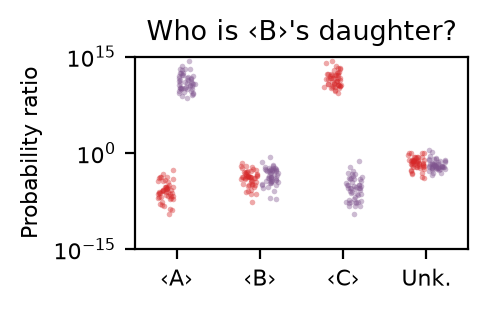

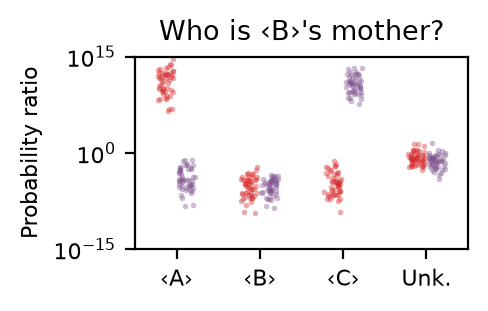

In [4]:
FIGURE_SPECS = (
    ('B --daughter--> ?', "Who is ‹B›'s daughter?", 'who_is_Bs_daughter.svg'),
    ('B --mother--> ?', "Who is ‹B›'s mother?", 'who_is_Bs_mother.svg'),
)

for query, title, filename in FIGURE_SPECS:
    plot = plot_figure_3_query(query, title, filename)
    display(plot.fig)
    plt.close(plot.fig)
